# Prioritising proactive technical support for Company A

**Decision.** With a limited contact budget, whom should Customer Care offer a technical check after signs of repeated dropped or blocked calls?

**Outcome.** The data dictionary defines churn as leaving on days 31–60 after the observation date. One row represents one customer. The aim is to rank customers who already qualify for a technical check and then test whether the support actually reduces churn.

**Run from top to bottom.** Use Python with pandas, NumPy, SciPy, scikit-learn, Matplotlib and Jupyter.

## Dataset files

Use the two CSVs supplied by GCI in the course folder `Final Assignment/telecom/`.

| File | What it contains |
| --- | --- |
| `Client.csv` | Customer profiles, account information and device details |
| `Record.csv` | Usage, billing, call quality and the `churn` label |

The CSVs stay in separate files. The notebook displays saved analysis outputs and reads both CSVs with `pd.read_csv` under **2. Join and check the two source tables** when you run it.

To rerun the analysis, place both CSVs together in a `telecom/` folder next to this notebook, or set `DATA_DIR` in the first code cell to the folder that contains both files. On Colab, mount Google Drive first and set `DATA_DIR` to the folder on your mounted Drive.

## 1. Market context and business hypothesis

Indonesia is an illustrative market for this proposal because Company A's geography is unspecified.

- Telkom estimated **322.8 million cellular subscribers** in Indonesia at the end of 2025, up from 312.9 million in 2024. Its filing names Telkomsel, Indosat Ooredoo Hutchison and XLSmart as the three largest operators by subscriptions. Multi-SIM use matters when interpreting subscriber totals. [Telkom Indonesia FY2025 Form 20-F, Item 4B, p. 95][telkom-filing]
- Telkom describes network quality as part of Telkomsel's 2026 strategy to reduce customer switching. [Telkom FY2025 results announcement, 12 May 2026][telkom-results]
- Komdigi's March 2026 holiday monitoring recorded **33 service disruptions at key monitoring points** and reported that operators proactively mitigated tickets. This describes operations during a specific period. [Komdigi RAFI 2026 evaluation, 10 April 2026][komdigi]

**Hypothesis to test.** Customers with a higher share of dropped or blocked calls have higher observed churn within comparable tenure groups. If that pattern survives basic checks, test whether a model can better prioritise eligible customers for troubleshooting. The market sources motivate the action. Company A's data determines the segments and the observed patterns.

[telkom-filing]: https://www.telkom.co.id/minio/show/data/lampiran/1778861459016_original_PERUSAHAAN-PERSEROAN-PERSERO-PT-TELEKOMUNIKASI-INDONESIA-TBK-20260515-20-F-EDGAR.pdf
[telkom-results]: https://www.telkom.co.id/sites/berita/id_ID/news/laporan-keuangan-telkom-tahun-buku-2025-telkom-telkom-bukukan-kinerja-fy25-resilience-perkuat-fundamental-dan-hasilkan-total-shareholder-return-357-3767
[komdigi]: https://portal.komdigi.go.id/kanal-publik/berita-kini/10145

## 2. Join and check the two source tables

The join uses the supplied `Customer_ID`. We check uniqueness and reconcile the keys before merging. The notebook never uses the ID as a model input or displays customer-level rows. The checks below also flag implausible equipment ages and unusual revenue values. Negative equipment ages are treated as missing. Nonpositive revenue is counted and excluded from the financial proxy, whose coverage is reported.

In [1]:
from pathlib import Path
from math import ceil
from statistics import NormalDist

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, PercentFormatter
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy.stats import beta
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_DIR = None  # Set to the folder containing Client.csv and Record.csv if needed.
SEED = 42
MIN_ATTEMPTS = 20
FAILURE_THRESHOLD = 0.10
CONTACT_SHARE = 0.10

project_dir = Path.cwd()
candidates = [
    project_dir / "telecom",
    project_dir / "Final Assignment" / "telecom",
    project_dir.parent / "05. Final Assignment (due Nov 28)" / "Final Assignment" / "telecom",
]
if DATA_DIR is not None:
    candidates = [Path(DATA_DIR).expanduser()]
data_dir = next(
    (folder for folder in candidates
     if all((folder / name).is_file() for name in ("Client.csv", "Record.csv"))),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Set DATA_DIR to the folder containing Client.csv and Record.csv.")

pd.set_option("display.max_columns", None)
print(f"Library versions: pandas {pd.__version__}, NumPy {np.__version__}, "
      f"SciPy {scipy.__version__}, scikit-learn {sklearn.__version__}.")

Library versions: pandas 3.1.1, NumPy 2.5.4, SciPy 1.18.1, scikit-learn 1.9.1.


In [2]:
key = "Customer_ID"
client = pd.read_csv(data_dir / "Client.csv", dtype={key: "string"})
record = pd.read_csv(data_dir / "Record.csv", dtype={key: "string"})
quality = pd.DataFrame(
    [{"Table": name, "Rows": len(frame), "Columns": frame.shape[1],
      "Missing IDs": frame[key].isna().sum(), "Duplicate IDs": frame[key].duplicated().sum()}
     for name, frame in (("Client.csv", client), ("Record.csv", record))]
)
display(quality)
if quality[["Missing IDs", "Duplicate IDs"]].to_numpy().any():
    raise ValueError("Resolve missing or duplicate IDs before joining.")

key_coverage = record[[key]].merge(client[[key]], how="outer", on=key, indicator=True)
coverage = key_coverage["_merge"].value_counts()
display(coverage.rename({"left_only": "Record only", "right_only": "Client only",
                         "both": "Matched"}).rename("Customers").to_frame())
if (key_coverage["_merge"] != "both").any():
    raise ValueError("The two source tables contain unmatched customer IDs.")
data = record.merge(client, on=key, how="inner", validate="one_to_one")
if data["churn"].isna().any() or set(data["churn"].unique()) != {0, 1}:
    raise ValueError("Expected both binary churn labels and no missing labels.")

audit = pd.DataFrame({
    "Missing": data[["attempt_Mean", "drop_blk_Mean", "months", "rev_Mean",
                     "mou_Mean", "custcare_Mean", "eqpdays"]].isna().sum(),
    "Negative": data[["attempt_Mean", "drop_blk_Mean", "months", "rev_Mean",
                      "mou_Mean", "custcare_Mean", "eqpdays"]].lt(0).sum(),
})
display(audit)
print(f"Joined table: {len(data):,} customers, {data.shape[1]} columns.")
print(f"Historical churn label: {data['churn'].sum():,} customers ({data['churn'].mean():.2%}).")

,Table,Rows,Columns,Missing IDs,Duplicate IDs
0,Client.csv,100000,50,0,0
1,Record.csv,100000,51,0,0


,Customers
_merge,
Matched,100000
Record only,0
Client only,0


,Missing,Negative
attempt_Mean,0,0
drop_blk_Mean,0,0
months,0,0
rev_Mean,357,5
mou_Mean,357,0
custcare_Mean,0,0
eqpdays,1,133


Joined table: 100,000 customers, 100 columns.
Historical churn label: 49,562 customers (49.56%).


In [3]:
# A ratio of customer-level means is a service-friction proxy.
attempts = data["attempt_Mean"]
failures = data["drop_blk_Mean"]
positive_attempts = attempts.gt(0)
valid_ratio = positive_attempts & failures.ge(0) & failures.le(attempts + 1e-6)
data["failure_share"] = failures.div(attempts.where(valid_ratio)).clip(upper=1)
data["tenure_band"] = pd.cut(
    data["months"], bins=[5, 11, 23, np.inf], labels=["6–11", "12–23", "24+"]
)
ratio_status = pd.Series({
    "No positive attempts or missing attempts": int((~positive_attempts).sum()),
    "Positive attempts with an invalid numerator": int((positive_attempts & ~valid_ratio).sum()),
    "Valid ratios with fewer than the minimum attempts": int(
        (valid_ratio & attempts.lt(MIN_ATTEMPTS)).sum()
    ),
    "Valid ratios at or above the minimum attempts": int(
        (valid_ratio & attempts.ge(MIN_ATTEMPTS)).sum()
    ),
}, name="Customers")
display(ratio_status.to_frame())

,Customers
No positive attempts or missing attempts,8160
Positive attempts with an invalid numerator,4
Valid ratios with fewer than the minimum attempts,8745
Valid ratios at or above the minimum attempts,83091


## 3. Validate the service-friction hypothesis

**Measure.** Divide the mean number of dropped or blocked calls by the mean number of attempted calls. The source provides customer-level aggregates, so this serves as a troubleshooting signal. The calculation uses compatible counts as an assumption to verify with the client before deployment.

**Main comparison.** Use the agreed screening thresholds of at least 20 mean attempts and a failure share above 10%. The first chart compares churn within tenure bands, with 95% exact binomial intervals. The second checks sensitivity across nine cutoff combinations and shows the within-tenure differences. These are descriptive comparisons. The data also leaves out dates and specific reasons for churn, so differences may reflect other customer characteristics or sample selection.

,Customers at or below cutoff,Churn at or below cutoff (%),Customers above cutoff,Churn above cutoff (%),Difference (pp)
tenure_band,,,,,
6–11,17076,40.87,4870,45.69,4.82
12–23,31290,51.06,7513,56.09,5.03
24+,18758,47.47,3584,52.09,4.62


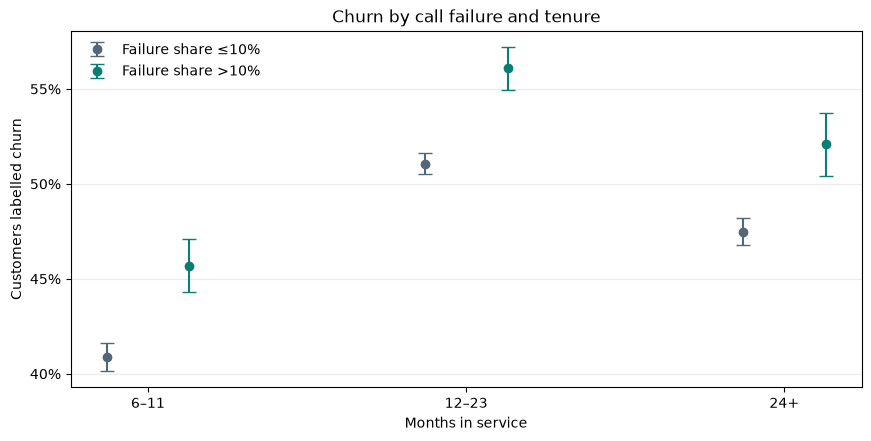

In [4]:
def compare_churn(min_attempts, failure_threshold):
    cohort = data.loc[
        data["attempt_Mean"].ge(min_attempts)
        & data["failure_share"].notna()
        & data["tenure_band"].notna(),
        ["tenure_band", "failure_share", "churn"],
    ].copy()
    cohort["Above threshold"] = cohort["failure_share"].gt(failure_threshold)
    result = cohort.groupby(["tenure_band", "Above threshold"], observed=True)["churn"].agg(
        Churns="sum", Customers="size"
    )
    result["Churn share"] = result["Churns"] / result["Customers"]
    result["Lower 95%"] = beta.ppf(0.025, result["Churns"], result["Customers"] - result["Churns"] + 1)
    result["Upper 95%"] = beta.ppf(0.975, result["Churns"] + 1, result["Customers"] - result["Churns"])
    result.loc[result["Churns"].eq(0), "Lower 95%"] = 0
    result.loc[result["Churns"].eq(result["Customers"]), "Upper 95%"] = 1
    return result


eda = compare_churn(MIN_ATTEMPTS, FAILURE_THRESHOLD)
eda_rates = eda["Churn share"].unstack("Above threshold")
eda_counts = eda["Customers"].unstack("Above threshold")
comparisons = pd.DataFrame({
    "Customers at or below cutoff": eda_counts[False],
    "Churn at or below cutoff (%)": 100 * eda_rates[False],
    "Customers above cutoff": eda_counts[True],
    "Churn above cutoff (%)": 100 * eda_rates[True],
    "Difference (pp)": 100 * (eda_rates[True] - eda_rates[False]),
})
display(comparisons.round(2))

fig, ax = plt.subplots(figsize=(8.6, 4.3), layout="constrained")
x_positions = np.arange(len(eda_rates))
for above, offset, color in ((False, -0.13, "#536779"), (True, 0.13, "#087e75")):
    group = eda.xs(above, level="Above threshold")
    rates = group["Churn share"]
    errors = np.vstack([rates - group["Lower 95%"], group["Upper 95%"] - rates])
    comparison = ">" if above else "≤"
    ax.errorbar(x_positions + offset, rates, yerr=errors, fmt="o", capsize=5,
                color=color, label=f"Failure share {comparison}{FAILURE_THRESHOLD:.0%}")
ax.set(title="Churn by call failure and tenure", xlabel="Months in service",
       ylabel="Customers labelled churn", xticks=x_positions, xticklabels=eda_rates.index)
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, loc="best")
plt.show()

Churn difference in percentage points, above cutoff minus at or below cutoff:


tenure_band                  6–11  12–23   24+
Min attempts Failure cutoff                   
10           0.05            2.55   3.85  2.92
             0.10            4.85   4.77  4.77
             0.15            4.75   5.97  5.69
20           0.05            2.49   3.94  2.71
             0.10            4.82   5.03  4.62
             0.15            4.75   6.34  5.57
40           0.05            2.40   4.16  2.87
             0.10            4.68   5.15  4.85
             0.15            4.12   6.03  5.21

Customers above cutoff:


tenure_band                   6–11  12–23    24+
Min attempts Failure cutoff                     
10           0.05            13364  22830  12615
             0.10             5141   8078   3995
             0.15             2371   3554   1577
20           0.05            12875  21676  11733
             0.10             4870   7513   3584
             0.15             2216   3245   1364
40           0.05            11831  19365  10255
             0.10             4363   6497   2978
             0.15             1961   2756   1092

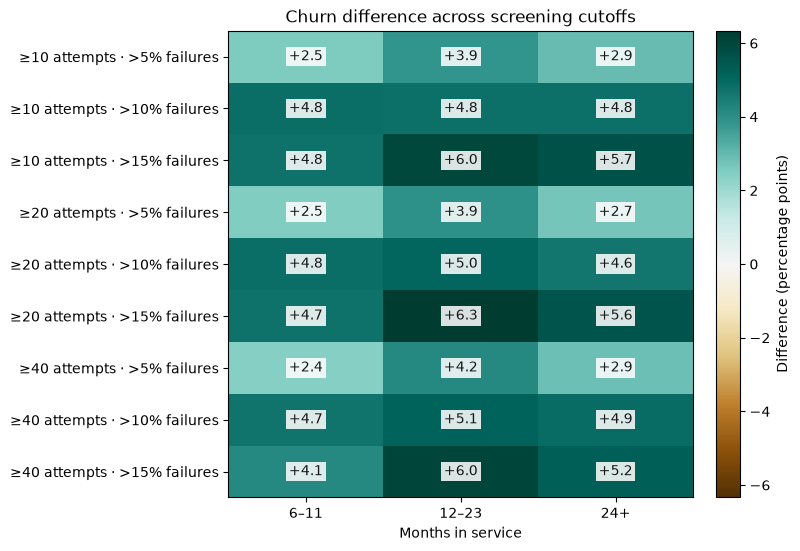

Positive differences: 27 of 27 combinations of tenure and cutoff.


In [5]:
alternative_attempts = sorted({10, MIN_ATTEMPTS, 40})
alternative_thresholds = sorted({0.05, FAILURE_THRESHOLD, 0.15})
sensitivity_rows = []
for minimum in alternative_attempts:
    for cutoff in alternative_thresholds:
        comparison = compare_churn(minimum, cutoff).unstack("Above threshold")
        for tenure_band, row in comparison.iterrows():
            sensitivity_rows.append({
                "Min attempts": minimum,
                "Failure cutoff": cutoff,
                "Months in service": tenure_band,
                "Customers above cutoff": row["Customers", True],
                "Churn difference (pp)": 100 * (row["Churn share", True] - row["Churn share", False]),
            })

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity_matrix = sensitivity.pivot(
    index=["Min attempts", "Failure cutoff"],
    columns="Months in service",
    values="Churn difference (pp)",
).reindex(columns=eda_rates.index)
above_counts = sensitivity.pivot(
    index=["Min attempts", "Failure cutoff"],
    columns="Months in service",
    values="Customers above cutoff",
).reindex(columns=eda_rates.index)
print("Churn difference in percentage points, above cutoff minus at or below cutoff:")
display(sensitivity_matrix.round(2))
print("Customers above cutoff:")
display(above_counts.astype("Int64"))

fig, ax = plt.subplots(figsize=(7.9, 5.4), layout="constrained")
delta = sensitivity_matrix.to_numpy(dtype=float)
heatmap = ax.imshow(delta, aspect="auto", cmap="BrBG",
                   vmin=-np.nanmax(np.abs(delta)), vmax=np.nanmax(np.abs(delta)))
for (row, col), value in np.ndenumerate(delta):
    ax.text(col, row, f"{value:+.1f}", ha="center", va="center", color="#171717",
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.86, "pad": 2})
ax.set(title="Churn difference across screening cutoffs", xlabel="Months in service",
       xticks=range(len(sensitivity_matrix.columns)), xticklabels=sensitivity_matrix.columns,
       yticks=range(len(sensitivity_matrix.index)),
       yticklabels=[f"≥{n} attempts · >{cutoff:.0%} failures"
                    for n, cutoff in sensitivity_matrix.index])
fig.colorbar(heatmap, ax=ax, label="Difference (percentage points)")
plt.show()
print(f"Positive differences: {sensitivity['Churn difference (pp)'].gt(0).sum()} "
      f"of {len(sensitivity)} combinations of tenure and cutoff.")

## 4. Compare two ways to fill the same contact quota

**Who is eligible?** A customer with a valid failure share above 10% and at least 20 mean call attempts. This supports a consistent intervention for both approaches. In a live pilot, eligibility also requires an active account and a permitted contact channel.

- **Call failure rule.** Sort eligible customers by failure share from highest to lowest.
- **Logistic regression.** Rank eligible customers by their estimated risk, using failure share, call volume, minutes of use, support usage, equipment age, and tenure bands. The model uses a small set of documented operational fields, with log transforms for skewed counts. It excludes customer IDs, demographic fields, amounts used in the pilot simulation and ambiguous billing-change fields. Predictors need confirmation that they can be recreated as of day 0.

A seeded, stratified 75/25 split is used within the eligible cohort. Median imputation and standardisation are fit on training rows only. The screening choices come from exploratory checks on this historical file. The split tests the ranking within that design. Validate it on a later operational cohort before rollout.

**Primary metric.** Precision at a 10% contact quota is the fraction of the shortlist that churned. Recall at the same quota shows the fraction of eligible churners on the list. ROC AUC measures ranking across the eligible holdout. The expected precision of random selection equals the eligible holdout churn share.

In [6]:
eligible = data.loc[
    data["attempt_Mean"].ge(MIN_ATTEMPTS) & data["failure_share"].gt(FAILURE_THRESHOLD)
].copy()

features = pd.DataFrame({
    "Call failure share": eligible["failure_share"],
    "Log attempted calls": np.log1p(eligible["attempt_Mean"]),
    "Log usage minutes": np.log1p(eligible["mou_Mean"].where(eligible["mou_Mean"].ge(0))),
    "Log support calls": np.log1p(eligible["custcare_Mean"].where(eligible["custcare_Mean"].ge(0))),
    "Equipment age": eligible["eqpdays"].where(eligible["eqpdays"].ge(0)),
})
for band in ("6–11", "12–23"):
    features[f"Tenure {band} months"] = eligible["tenure_band"].eq(band).astype(float).where(
        eligible["tenure_band"].notna()
    )
labels = eligible["churn"]
train, test = train_test_split(
    eligible.index.to_numpy(), test_size=0.25, stratify=labels, random_state=SEED
)
model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=SEED),
)
model.fit(features.loc[train], labels.loc[train])

rule_name = "Call failure rule"
model_name = "Logistic regression"
observed = labels.loc[test].to_numpy()
scores = {
    rule_name: eligible.loc[test, "failure_share"].to_numpy(),
    model_name: model.predict_proba(features.loc[test])[:, 1],
}
# Random seeded tie-breaking is independent of customer ID and churn.
tie_break = np.random.default_rng(SEED).random(len(test))
eligible_share = len(eligible) / len(data)
quota = ceil(CONTACT_SHARE * len(test))
print(f"Screened cohort: {len(eligible):,} of {len(data):,} customers ({eligible_share:.1%}).")
print(f"Training: {len(train):,}. Holdout: {len(test):,}. Contact quota: {quota:,}.")
print(f"Expected shortlist precision under random selection: {observed.mean():.1%}.")

Screened cohort: 15,967 of 100,000 customers (16.0%).
Training: 11,975. Holdout: 3,992. Contact quota: 400.
Expected shortlist precision under random selection: 52.0%.


In [7]:
def rank_order(score, tiebreak):
    return np.lexsort((tiebreak, -score))


ranked = {name: rank_order(score, tie_break) for name, score in scores.items()}
shortlisted = {name: order[:quota] for name, order in ranked.items()}
metric_rows = []
for name, indices in shortlisted.items():
    found = int(observed[indices].sum())
    metric_rows.append({
        "Approach": name,
        "Holdout ROC AUC": roc_auc_score(observed, scores[name]),
        "Contact slots": quota,
        "Observed churners on shortlist": found,
        "Precision at quota (%)": 100 * found / quota,
        "Recall at quota (%)": 100 * found / observed.sum(),
        "Lift over random": (found / quota) / observed.mean(),
    })
evaluation = pd.DataFrame(metric_rows).set_index("Approach")
display(evaluation.round(3))

# Paired bootstrap resamples holdout customers and reranks within each draw.
rng = np.random.default_rng(SEED + 1)
bootstrap_deltas = []
for _ in range(1200):
    sample = rng.integers(0, len(test), len(test))
    precision = [
        observed[sample[rank_order(scores[name][sample], tie_break[sample])[:quota]]].mean()
        for name in (rule_name, model_name)
    ]
    bootstrap_deltas.append(100 * (precision[1] - precision[0]))
delta_low, delta_high = np.quantile(bootstrap_deltas, [0.025, 0.975])
precision_delta = evaluation.loc[model_name, "Precision at quota (%)"] - evaluation.loc[
    rule_name, "Precision at quota (%)"
]
model_for_pilot = model_name if delta_low > 0 else rule_name
print(f"Model minus rule precision: {precision_delta:+.2f} pp "
      f"(95% paired bootstrap interval {delta_low:+.2f} to {delta_high:+.2f} pp).")
print(f"Scoring approach to validate on fresh operational data: {model_for_pilot}.")

,Holdout ROC AUC,Contact slots,Observed churners on shortlist,Precision at quota (%),Recall at quota (%),Lift over random
Approach,,,,,,
Call failure rule,0.511,400,219,54.75,10.544,1.052
Logistic regression,0.575,400,250,62.50,12.037,1.201


Model minus rule precision: +7.75 pp (95% paired bootstrap interval +2.00 to +13.75 pp).
Scoring approach to validate on fresh operational data: Logistic regression.


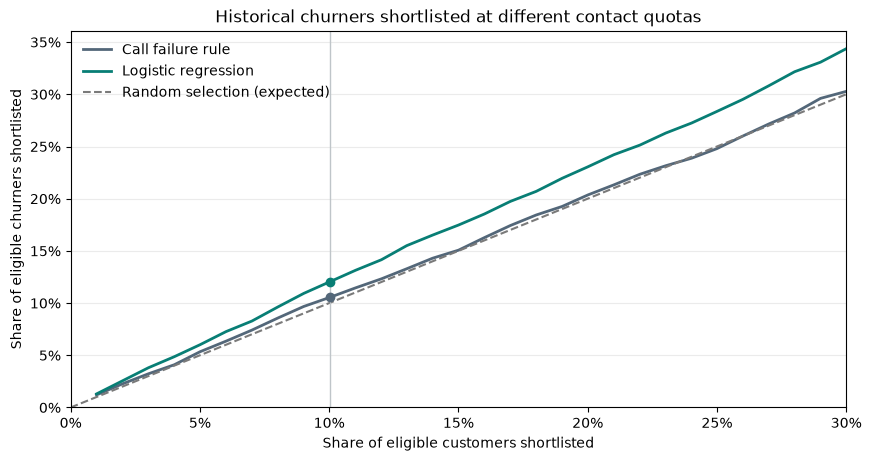

In [8]:
fig, ax = plt.subplots(figsize=(8.6, 4.5), layout="constrained")
fractions = np.linspace(0.01, 0.30, 30)
for name, color in ((rule_name, "#536779"), (model_name, "#087e75")):
    slots = np.ceil(fractions * len(test)).astype(int)
    capture = np.cumsum(observed[ranked[name]])[slots - 1] / observed.sum()
    ax.plot(slots / len(test), capture, color=color, label=name, linewidth=2)
    ax.scatter(quota / len(test), observed[shortlisted[name]].sum() / observed.sum(), color=color, zorder=3)
ax.plot([0, 0.30], [0, 0.30], linestyle="--", color="#7a7a7a", label="Random selection (expected)")
ax.axvline(quota / len(test), color="#bfc5c9", linewidth=1)
ax.set(title="Historical churners shortlisted at different contact quotas",
       xlabel="Share of eligible customers shortlisted",
       ylabel="Share of eligible churners shortlisted",
       xlim=(0, 0.30), ylim=(0, None))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, loc="upper left")
plt.show()

The bootstrap interval describes shortlist uncertainty conditional on these fitted scores and this holdout population. It omits the uncertainty from retraining and applying the policy in a new period. The rule is the fallback if the model's lower interval bound does not exceed zero. An outreach experiment is needed to measure whether support changes customers' decisions.

## 5. Estimate the economics and design the pilot

The dataset gives a monthly revenue proxy (`rev_Mean`) without a confirmed currency. Keep all inputs in the **same unspecified monetary units**, and replace them with finance and operations estimates before budgeting. Use the median positive monthly revenue among the selected holdout customers as a provisional valuation input. Treat cost, margin, duration, operational churn and treatment response as assumptions.

**Financial model per outreach batch.** Incremental retentions = contacts × assumed operational churn among the shortlisted customers without outreach × relative churn reduction from the outreach offer. Retained contribution = incremental retentions × monthly revenue proxy × contribution margin × additional retained months. Net contribution = retained contribution minus contact costs and fixed batch cost. The response rate is per person assigned outreach, including unsuccessful contacts.

Median monthly revenue proxy: 47.36 units (400/400 shortlist records with positive revenue).
Assumed contribution per incremental retention: 85.25 units.
Outreach cost for 1,000 assignments: 2,750 units.
Break-even: ≥33 incremental retentions, or a churn reduction of 3.23 percentage points before rounding.


,Control-group churn assumption (%),Break-even relative reduction (%)
0,5.0,64.51
1,10.0,32.26
2,20.0,16.13


,Control-group churn (%),Relative reduction (%),Expected incremental retentions,Net contribution (units)
0,5.0,5.0,2.5,-2536.9
1,5.0,15.0,7.5,-2110.6
2,5.0,30.0,15.0,-1471.2
3,10.0,5.0,5.0,-2323.7
4,10.0,15.0,15.0,-1471.2
5,10.0,30.0,30.0,-192.4
6,20.0,5.0,10.0,-1897.5
7,20.0,15.0,30.0,-192.4
8,20.0,30.0,60.0,2365.1


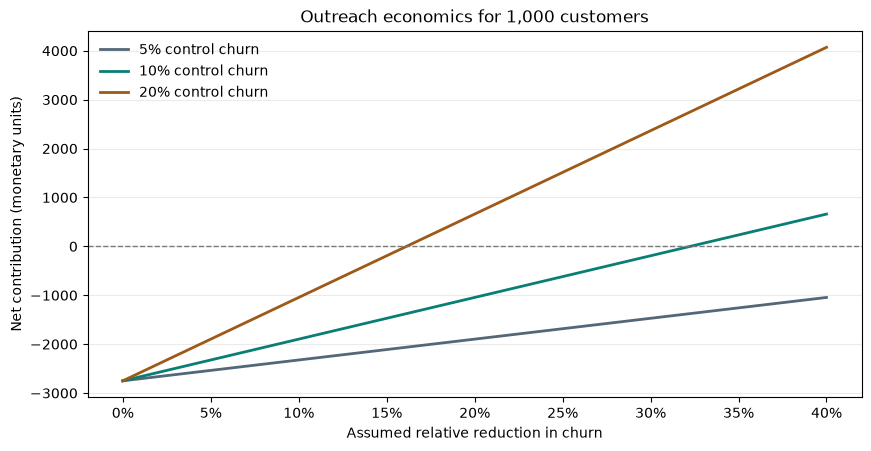

In [9]:
CONTACTS = 1000
COST_PER_CONTACT = 2.50
FIXED_BATCH_COST = 250.0
CONTRIBUTION_MARGIN = 0.45
ADDITIONAL_RETAINED_MONTHS = 4
CONTROL_CHURN_SCENARIOS = [0.05, 0.10, 0.20]
RELATIVE_REDUCTION_SCENARIOS = [0.05, 0.15, 0.30]

pilot_positions = shortlisted[model_for_pilot]
pilot_revenue = eligible.loc[test[pilot_positions], "rev_Mean"]
usable_revenue = pilot_revenue[pilot_revenue.gt(0)]
monthly_revenue_proxy = usable_revenue.median()
if not np.isfinite(monthly_revenue_proxy):
    raise ValueError("A positive monthly revenue proxy is required for the simulation.")

value_per_retention = monthly_revenue_proxy * CONTRIBUTION_MARGIN * ADDITIONAL_RETAINED_MONTHS
batch_cost = FIXED_BATCH_COST + CONTACTS * COST_PER_CONTACT
breakeven_absolute = batch_cost / (CONTACTS * value_per_retention)
minimum_customers_retained = ceil(batch_cost / value_per_retention)
print(f"Median monthly revenue proxy: {monthly_revenue_proxy:,.2f} units "
      f"({len(usable_revenue):,}/{len(pilot_revenue):,} shortlist records with positive revenue).")
print(f"Assumed contribution per incremental retention: {value_per_retention:,.2f} units.")
print(f"Outreach cost for {CONTACTS:,} assignments: {batch_cost:,.0f} units.")
print(f"Break-even: ≥{minimum_customers_retained} incremental retentions, "
      f"or a churn reduction of {100 * breakeven_absolute:.2f} percentage points before rounding.")
display(pd.DataFrame({
    "Control-group churn assumption (%)": [100 * risk for risk in CONTROL_CHURN_SCENARIOS],
    "Break-even relative reduction (%)": [100 * breakeven_absolute / risk for risk in CONTROL_CHURN_SCENARIOS],
}).round(2))

scenario_rows = []
for control_churn in CONTROL_CHURN_SCENARIOS:
    for relative_reduction in RELATIVE_REDUCTION_SCENARIOS:
        retained = CONTACTS * control_churn * relative_reduction
        scenario_rows.append({
            "Control-group churn (%)": 100 * control_churn,
            "Relative reduction (%)": 100 * relative_reduction,
            "Expected incremental retentions": retained,
            "Net contribution (units)": retained * value_per_retention - batch_cost,
        })
scenarios = pd.DataFrame(scenario_rows)
display(scenarios.round(1))

fig, ax = plt.subplots(figsize=(8.6, 4.4), layout="constrained")
effect_grid = np.linspace(0, 0.40, 81)
for control_churn, color in zip(CONTROL_CHURN_SCENARIOS, ("#536779", "#087e75", "#9c5917")):
    net = CONTACTS * control_churn * effect_grid * value_per_retention - batch_cost
    ax.plot(effect_grid, net, label=f"{control_churn:.0%} control churn", color=color, linewidth=2)
ax.axhline(0, linestyle="--", color="#7a7a7a", linewidth=1)
ax.set(title=f"Outreach economics for {CONTACTS:,} customers",
       xlabel="Assumed relative reduction in churn", ylabel="Net contribution (monetary units)")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
plt.show()

### Pilot protocol

1. **Validate inputs on a fresh cohort.** Customer Care and the network team check that the ratio uses compatible counts, that all predictors are available on day 0, that the data is current and that customers are reachable through an approved channel. Measure shortlist churn in a recent, untreated cohort before sizing the experiment.
2. **Randomise equally within shortlisted customers.** Assign the outreach group an SMS inviting a technical check with escalation where needed. Give the control group usual care. Stratify by tenure and risk tier if operationally possible, prevent repeat assignments, and keep each customer's group fixed even if they never respond.
3. **Measure effects and costs.** The primary outcome is the difference in days 31–60 churn across assigned groups. Also monitor days 0–60 churn, resolution, opt-outs, complaints, cost per assignment and contribution over the follow-up period. Avoid scaling if service issues or complaints increase materially.
4. **Make the scale decision against measured economics.** Compare the estimated incremental retention and its confidence interval with the break-even reduction using observed costs and updated contribution. A pilot sized only to detect a difference from zero may yield too much uncertainty to approve scaling. Keep the 1,000-contact batch as a financial reporting unit and size the experiment independently.

In [10]:
# Size for the lower end of a 95% interval to exceed economic break-even with 80% power.
assumed_control_churn = 0.20
assumed_relative_reduction = 0.30
expected_reduction = assumed_control_churn * assumed_relative_reduction
headroom = expected_reduction - breakeven_absolute
control_variance = assumed_control_churn * (1 - assumed_control_churn)
if headroom > 0:
    treatment_at_threshold = assumed_control_churn - breakeven_absolute
    expected_treatment_churn = assumed_control_churn - expected_reduction
    variance_at_threshold = control_variance + treatment_at_threshold * (1 - treatment_at_threshold)
    variance_at_expected = control_variance + expected_treatment_churn * (1 - expected_treatment_churn)
    z_alpha = NormalDist().inv_cdf(0.975)
    z_power = NormalDist().inv_cdf(0.80)
    sample_per_arm = ceil((
        z_alpha * np.sqrt(variance_at_threshold) + z_power * np.sqrt(variance_at_expected)
    ) ** 2 / headroom ** 2)
    print(f"Approximate sample size: {sample_per_arm:,} customers per arm to show that the "
          f"reduction exceeds break-even when control churn is {assumed_control_churn:.0%} "
          f"and the true absolute reduction is {100 * expected_reduction:.1f} pp.")
else:
    print("The assumed effect falls at or below break-even. Sample size cannot resolve that gap.")
print("Use current churn, costs and a plausible treatment effect before committing to an experiment size.")

Approximate sample size: 2,996 customers per arm to show that the reduction exceeds break-even when control churn is 20% and the true absolute reduction is 6.0 pp.
Use current churn, costs and a plausible treatment effect before committing to an experiment size.


## 6. Results to carry into the proposal

The first number below summarizes the association seen in the data. The holdout result assesses who to contact under a fixed quota. The final number is an economic threshold for the experiment, calculated under stated assumptions.

In [11]:
differences = comparisons["Difference (pp)"]
print(f"Service friction: churn is {differences.min():.1f} to {differences.max():.1f} pp higher "
      f"above the {FAILURE_THRESHOLD:.0%} failure-share cutoff across the three tenure groups.")
print(f"Shortlist: at the top {CONTACT_SHARE:.0%} quota, the rule selects "
      f"{evaluation.loc[rule_name, 'Observed churners on shortlist']:.0f} historical churners and "
      f"logistic regression selects {evaluation.loc[model_name, 'Observed churners on shortlist']:.0f} "
      f"out of the same {quota:,} contact slots.")
print(f"Proposed next decision: validate {model_for_pilot.lower()} on a recent cohort, then randomise outreach. "
      f"With the current budget assumptions, the batch needs about {100 * breakeven_absolute:.2f} pp less churn to break even.")

Service friction: churn is 4.6 to 5.0 pp higher above the 10% failure-share cutoff across the three tenure groups.
Shortlist: at the top 10% quota, the rule selects 219 historical churners and logistic regression selects 250 out of the same 400 contact slots.
Proposed next decision: validate logistic regression on a recent cohort, then randomise outreach. With the current budget assumptions, the batch needs about 3.23 pp less churn to break even.


## References

- Matsuo–Iwasawa Lab, University of Tokyo. GCI World Final Assignment README and Company A Dataset Overview. Course-supplied `Client.csv` and `Record.csv`.
- PT Telekomunikasi Indonesia Tbk. [FY2025 Form 20-F, Item 4B, p. 95](https://www.telkom.co.id/minio/show/data/lampiran/1778861459016_original_PERUSAHAAN-PERSEROAN-PERSERO-PT-TELEKOMUNIKASI-INDONESIA-TBK-20260515-20-F-EDGAR.pdf).
- Telkom Indonesia. [FY2025 results announcement, 12 May 2026](https://www.telkom.co.id/sites/berita/id_ID/news/laporan-keuangan-telkom-tahun-buku-2025-telkom-telkom-bukukan-kinerja-fy25-resilience-perkuat-fundamental-dan-hasilkan-total-shareholder-return-357-3767).
- Kementerian Komunikasi dan Digital. [RAFI 2026 evaluation, 10 April 2026](https://portal.komdigi.go.id/kanal-publik/berita-kini/10145).
- scikit-learn. [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) and [ROC AUC score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).
- Clopper, C. J. and Pearson, E. S. (1934). The use of confidence or fiducial limits illustrated in the case of the binomial. [Biometrika, 26(4), 404–413](https://doi.org/10.1093/biomet/26.4.404).